# EARTHSC 5201: Homework 2
## Rory Levinson

### Question 1

#### Using the normal mode example in Lecture 6, plot the sum of the first 40 modes at t=1.5, 5, and 10. The length of the string is 20, the velocity is 3, and the location of the source x_s=8. For the x-axis, discretize this into units of length 0.1. Use the same expression for F(w_n) and the normal mode summation on slide 26 (the number in the lower corner of Lecture 6). Use 1 for the value of tau in the F(w_n) equation. The time slice at 1.5 seconds should be identical to the figure on slide 27, but what are the changes at 5 and 10 seconds that you observe?

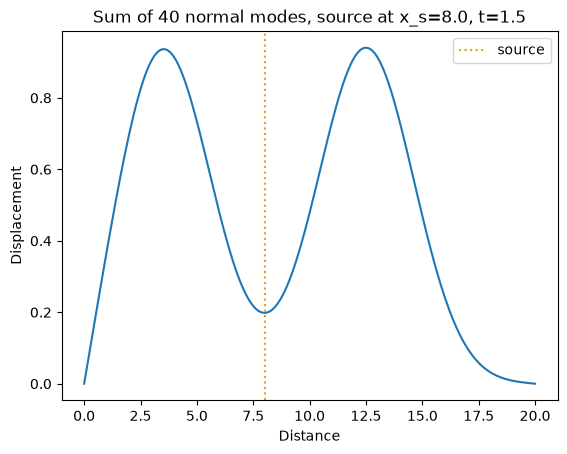

In [1]:
import numpy as np
import matplotlib.pyplot as plt

L, c, xs, t_snap = 20.0, 3.0, 8.0, 1.5
x = np.linspace(0, L, 201)

def mode_sum(x, xs, t, n_modes=40, tau_src=1.0, L=20.0, c=3.0):
    u = np.zeros_like(x)
    for n in range(1, n_modes + 1):
        wn = n * np.pi * c / L
        An = np.sin(n * np.pi * xs / L) * np.exp(-(wn * tau_src) ** 2 / 4)
        Un = np.sin(n * np.pi * x / L)
        u += An * Un * np.cos(wn * t)
    return u

u_sum = mode_sum(x, xs, t_snap)

plt.plot(x, u_sum)
plt.axvline(xs, color="goldenrod", linestyle=":", label="source")
plt.xlabel("Distance"); plt.ylabel("Displacement")
plt.title(f"Sum of 40 normal modes, source at x_s={xs}, t={t_snap}")
plt.legend()
plt.show()

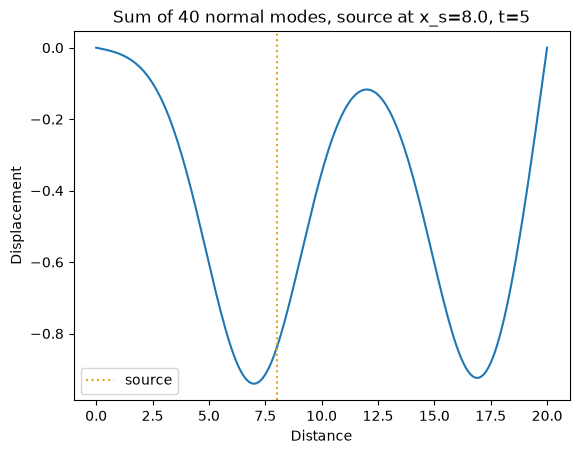

In [2]:
import numpy as np
import matplotlib.pyplot as plt

L, c, xs, t_snap = 20.0, 3.0, 8.0, 5
x = np.linspace(0, L, 201)

def mode_sum(x, xs, t, n_modes=40, tau_src=1.0, L=20.0, c=3.0):
    u = np.zeros_like(x)
    for n in range(1, n_modes + 1):
        wn = n * np.pi * c / L
        An = np.sin(n * np.pi * xs / L) * np.exp(-(wn * tau_src) ** 2 / 4)
        Un = np.sin(n * np.pi * x / L)
        u += An * Un * np.cos(wn * t)
    return u

u_sum = mode_sum(x, xs, t_snap)

plt.plot(x, u_sum)
plt.axvline(xs, color="goldenrod", linestyle=":", label="source")
plt.xlabel("Distance"); plt.ylabel("Displacement")
plt.title(f"Sum of 40 normal modes, source at x_s={xs}, t={t_snap}")
plt.legend()
plt.show()

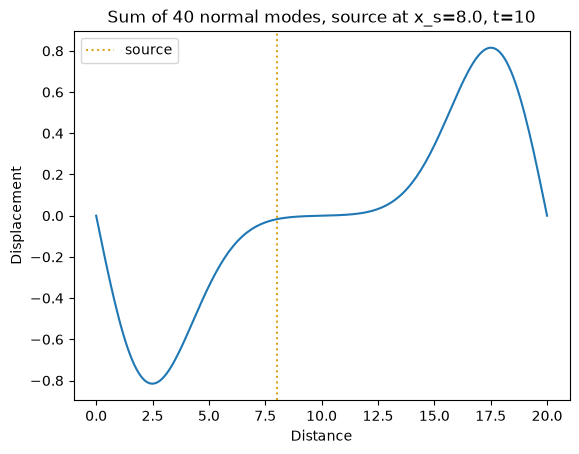

In [3]:
import numpy as np
import matplotlib.pyplot as plt

L, c, xs, t_snap = 20.0, 3.0, 8.0, 10
x = np.linspace(0, L, 201)

def mode_sum(x, xs, t, n_modes=40, tau_src=1.0, L=20.0, c=3.0):
    u = np.zeros_like(x)
    for n in range(1, n_modes + 1):
        wn = n * np.pi * c / L
        An = np.sin(n * np.pi * xs / L) * np.exp(-(wn * tau_src) ** 2 / 4)
        Un = np.sin(n * np.pi * x / L)
        u += An * Un * np.cos(wn * t)
    return u

u_sum = mode_sum(x, xs, t_snap)

plt.plot(x, u_sum)
plt.axvline(xs, color="goldenrod", linestyle=":", label="source")
plt.xlabel("Distance"); plt.ylabel("Displacement")
plt.title(f"Sum of 40 normal modes, source at x_s={xs}, t={t_snap}")
plt.legend()
plt.show()

##### At t = 1.5 s, displacement is concentrated around the source, creating two positive peaks on either side. At t = 5 s, displacement is now mostly negative, and the peaks are no longer centered around the source. Instead, the wave extends over much more of the string. At t = 10 s, displacement is negative on the left side of the source and positive on the right side. The peaks are also not centered around the source, as the middle of the displacement peaks are slightly to the right overall.

### Question 2

#### A downgoing P-wave in a medium with a P velocity of 6 km/s travels through this “corner” shaped structure. If the incident ray is at an angle of 60 degrees from the horizontal and the final ray is at an angle of 75 degrees from the vertical, what is the P velocity within the corner shaped medium?

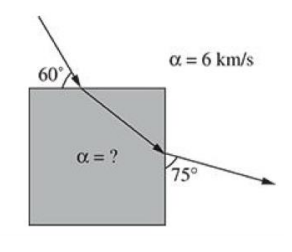

In [4]:
import numpy as np

v_incident = 6.0

theta_in = 90 - 60
theta_out = 90 - 75

p = np.sin(np.radians(theta_in)) / v_incident

v_corner = np.sin(np.radians(theta_out)) / p

print("Ray parameter:", p)
print("Velocity inside corner:", v_corner, "km/s")

Ray parameter: 0.08333333333333333
Velocity inside corner: 3.105828541230249 km/s


### Question 3a

#### Using the obspy taup function, create a version of figure 4.19 using the ak135 velocity model with 0.1 degree grid spacing and a source depth of 40 km. A hint to extract the travel time values, if you have:
#### arrivals=model.get_travel_times(source_depth_in_km=40,distance_in_degree=5)
#### Numarrivals = len(arrivals)
#### Arrivaltime = arrivals[0].time
#### You can loop over the number of arrivals and extract the arrival times in sequential order. You will want to plot each theoretical arrival as a dot rather than a line.

#### Figure 4.19:
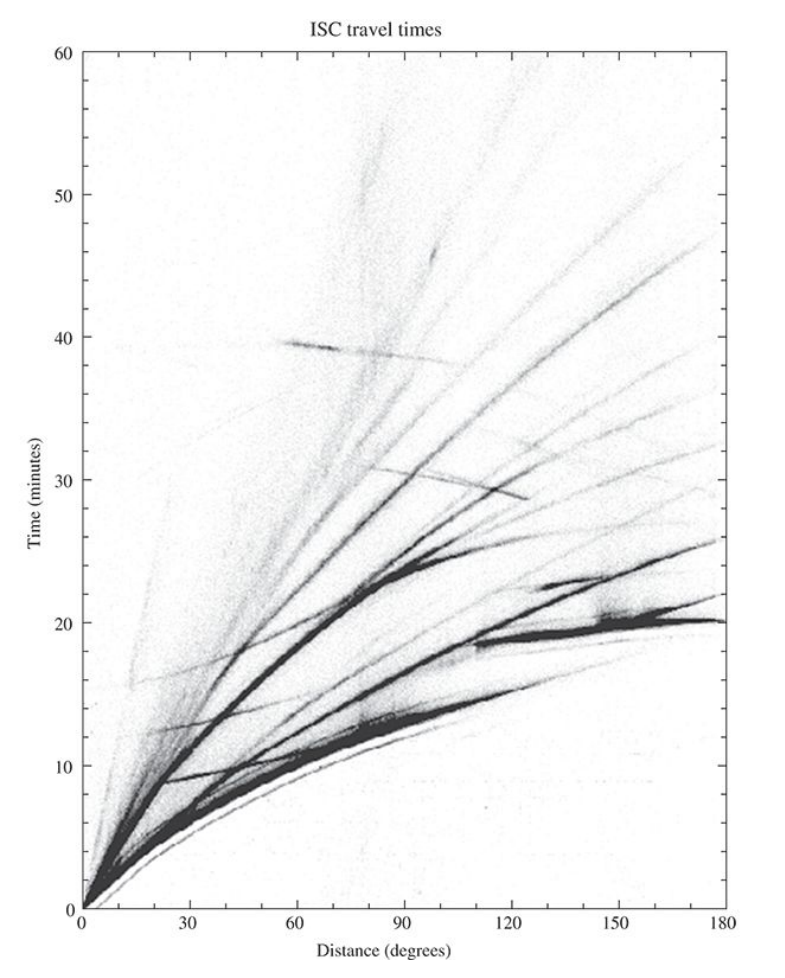

In [5]:
!mamba install obspy

mambajs 0.21.4

Specs: xeus-python, numpy, matplotlib, pillow, ipywidgets>=8.1.6, ipyleaflet, scipy, obspy
Channels: emscripten-forge-4x, conda-forge

Solving environment...
Solving took 1.556 seconds
  Name                Version    Build                Channel
---------------------------------------------------------------------------
+ annotated-doc       0.0.5      pyhcf101f3_0         conda-forge
+ backports           1.0        pyhd8ed1ab_5         conda-forge
+ backports.tarfile   1.2.0      pyhcf101f3_2         conda-forge
+ brotli-python       1.2.0      py313ha26e73d_2      emscripten-forge-4x
+ certifi             2026.7.22  pyhd8ed1ab_0         conda-forge
+ charset-normalizer  3.5.1      pyhd8ed1ab_0         conda-forge
+ colorama            0.4.6      pyhd8ed1ab_1         conda-forge
+ idna                3.20       pyh5ded981_0         conda-forge
+ jaraco.context      6.1.2      pyhcf101f3_0         conda-forge
+ jaraco.functools    4.6.0      pyhcf101f3_0         conda

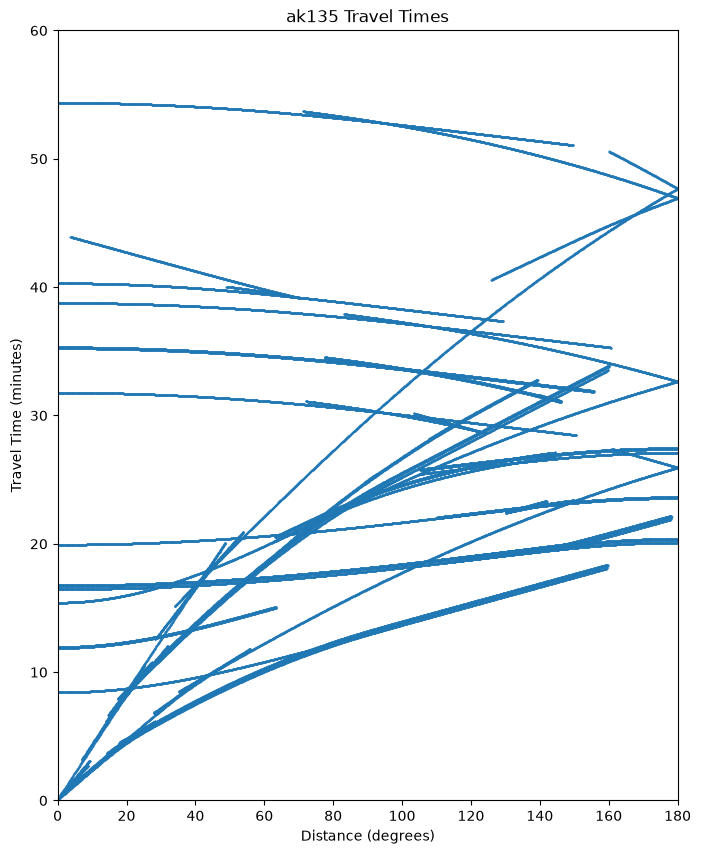

In [21]:
import numpy as np
import matplotlib.pyplot as plt
from obspy.taup import TauPyModel

model = TauPyModel(model="ak135")

distances = np.arange(0.1, 180.1, 0.1)

x = []
y = []
phases = []

for distance in distances:
    arrivals = model.get_travel_times(
        source_depth_in_km=40,
        distance_in_degree=distance
    )

    for arrival in arrivals:
        if arrival.time <= 3600:
            x.append(distance)
            y.append(arrival.time / 60)
            phases.append(arrival.name)

plt.figure(figsize=(8, 10))
plt.plot(x, y, '.', markersize=1)

plt.xlim(0, 180)
plt.ylim(0, 60)

plt.xlabel("Distance (degrees)")
plt.ylabel("Travel Time (minutes)")
plt.title("ak135 Travel Times")

plt.show()

### Question 3b

#### Find a broadband station (HHZ) that is roughly 90 degrees away from an earthquake of magnitude 7.5 out to 1 hour. Label any of the theoretical phase arrivals from taup on your plot. You may need to play around with filtering to observe additional arrivals.

In [9]:
from obspy import UTCDateTime
from obspy.clients.fdsn import Client
client_events = Client("https://earthquake.usgs.gov", _discover_services=False)

event1 = client_events.get_events(
    starttime=UTCDateTime("2005-09-25"),
    endtime=UTCDateTime("2005-09-27"),
    minmagnitude=7.4,
    maxmagnitude=7.6,
)
print(event1)

event = event1[0]
origin = event.preferred_origin() or event.origins[0]
magnitude = event.preferred_magnitude() or event.magnitudes[0]

print(f"{origin.time}  M{magnitude.mag:.1f}  "
      f"lat={origin.latitude:.2f}, lon={origin.longitude:.2f}, depth={origin.depth/1000:.1f} km")

1 Event(s) in Catalog:
2005-09-26T01:55:37.670000Z |  -5.678,  -76.398 | 7.5  mwb | manual
2005-09-26T01:55:37.670000Z  M7.5  lat=-5.68, lon=-76.40, depth=115.0 km


In [10]:
client = Client("https://service.earthscope.org", _discover_services=False)

inventory = client.get_stations(
    starttime=origin.time,
    endtime=origin.time + 3600,
    latitude=origin.latitude,
    longitude=origin.longitude,
    minradius=85,
    maxradius=90,
    channel="HHZ",
    level="channel"
)

print(inventory)

Inventory created at 2026-10-05T19:38:56.704000Z
	Created by: EarthScope WEB SERVICE: fdsnws-station | version: 1.1.58
		    https://service.earthscope.org/fdsnws/station/1/query?starttime=200...
	Sending institution: EarthScope (EarthScope)
	Contains:
		Networks (11):
			AK, BE, CA, CH, CN, GB, GE, IU, MN, XV, YM
		Stations (28):
			AK.DIV (Divide Microwave, AK, USA)
			AK.DOT (Dot Lake, AK, USA)
			AK.EYAK (Cordova Ski Area, AK, USA)
			AK.HARP (HAARP, AK, USA)
			AK.SWD (Seward, AK, USA)
			BE.UCC (Uccle, Brussels, Belgium)
			CA.CBRU (Bruguera)
			CA.CFON (Fontmartina)
			CA.CGAR (Garraf)
			CA.CLLI (Llivia)
			CH.BRANT (Les Verrieres)
			CH.SENIN (Lac Selin/Sanetsch)
			CN.EUNU (Eureka, NU, CA)
			GB.CWF (Charnwood Forest, Leicestershire, England, UK)
			GB.EDI (Edinburgh, Lothian, Scotland, UK)
			GB.ESK (Eskdalemuir, Dumfriesshire, Scotland, UK)
			GB.LRW (Lerwick, Shetland Islands, Scotland, UK)
			GE.DAG (GEOFON/AWI Station Danmarkshavn, Greenland)
			GE.MAHO (ROA/UCM/GEOFON S

In [15]:
t0 = origin.time
st = client.get_waveforms(
    network="AK", station="HARP", location="", channel="HHZ",
    starttime=t0, endtime=t0 + 3600,
)

In [17]:
from obspy.geodetics import locations2degrees

stations = [("AK", "HARP")]

for network, station in stations:

    inv = client.get_stations(
        network=network,
        station=station,
        channel="HHZ",
        starttime=origin.time,
        endtime=origin.time + 3600,
        level="station"
    )

    st = inv[0][0]

    distance = locations2degrees(
        origin.latitude,
        origin.longitude,
        st.latitude,
        st.longitude
    )

    print(
        network,
        station,
        "lat =", st.latitude,
        "lon =", st.longitude,
        "distance =", round(distance, 2), "degrees"
    )

AK HARP lat = 62.3986 lon = -145.1567 distance = 85.45 degrees


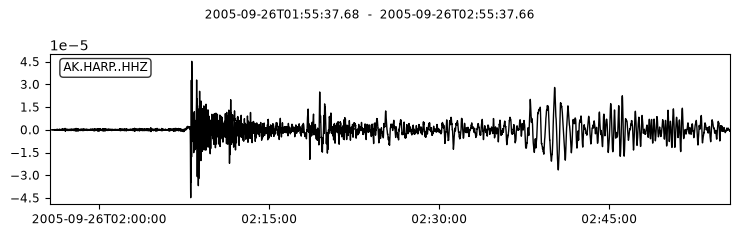

In [19]:
t0 = origin.time
st = client.get_waveforms(
    network="AK", station="HARP", location="", channel="HHZ",
    starttime=t0, endtime=t0 + 3600,
)

inv_resp = client.get_stations(
    network="AK", station="HARP", channel="HHZ", location="",
    starttime=t0, endtime=t0 + 3600,
    level="response",
)

st_corrected = st.copy()
st_corrected.remove_response(inventory=inv_resp, output="VEL")

st_corrected.filter("bandpass", freqmin=0.02, freqmax=9.99, corners=4, zerophase=True)

st_corrected.plot();

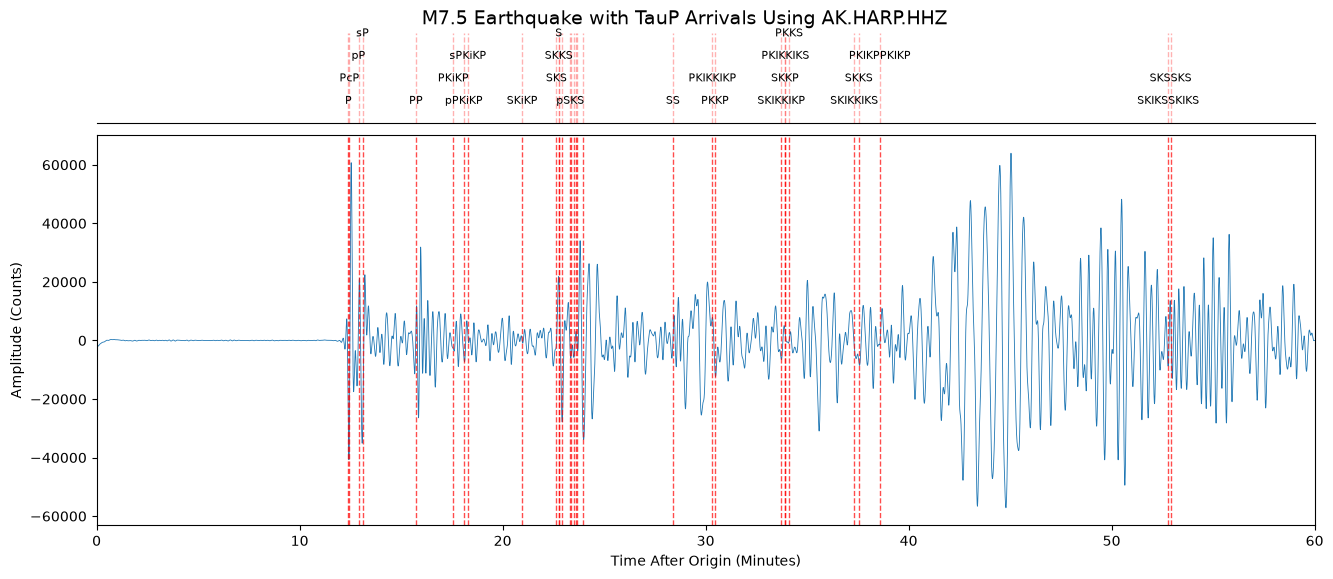

In [51]:
from obspy import UTCDateTime
from obspy.taup import TauPyModel
import matplotlib.pyplot as plt
import numpy as np

tr = st[0]
tr_filtered = tr.copy()
tr_filtered.filter(
    "bandpass",
    freqmin=0.01,
    freqmax=0.1,
    corners=4,
    zerophase=True
)

origin = UTCDateTime("2005-09-26T01:55:37.68")
distance = 85.4
depth = 115
model = TauPyModel(model="ak135")

arrivals = model.get_travel_times(
    source_depth_in_km=depth,
    distance_in_degree=distance
)

fig = plt.figure(figsize=(14, 6))

ax = fig.add_axes([
    0.08,
    0.12,
    0.87,
    0.65
])

phase_ax = fig.add_axes([
    0.08,
    0.79,
    0.87,
    0.15
])

times = tr_filtered.times(
    reftime=origin
) / 60

ax.plot(
    times,
    tr_filtered.data,
    linewidth=0.6
)

selected_arrivals = []

for arrival in arrivals:
    if arrival.time <= 3600:
        selected_arrivals.append(arrival)
        arrival_time = arrival.time / 60
        ax.axvline(
            arrival_time,
            color="red",
            linestyle="--",
            linewidth=1,
            alpha=0.7
        )
        phase_ax.axvline(
            arrival_time,
            color="red",
            linestyle="--",
            linewidth=1,
            alpha=0.3
        )

selected_arrivals.sort(
    key=lambda arrival: arrival.time
)

rows = [0.25, 0.50, 0.75, 1.0]
min_separation = 2.0
last_time_in_row = [-np.inf] * len(rows)

for arrival in selected_arrivals:
    arrival_time = arrival.time / 60
    for i, row in enumerate(rows):
        if arrival_time - last_time_in_row[i] >= min_separation:
            phase_ax.text(
                arrival_time,
                row,
                arrival.name,
                color="black",
                fontsize=8,
                ha="center",
                va="center"
            )
            last_time_in_row[i] = arrival_time
            break

ax.set_xlim(0, 60)
ax.set_xlabel(
    "Time After Origin (Minutes)"
)

ax.set_ylabel("Amplitude (Counts)")
phase_ax.set_xlim(0, 60)
phase_ax.set_ylim(0, 1)
phase_ax.set_xticks([])
phase_ax.set_yticks([])

fig.suptitle(
    "M7.5 Earthquake with TauP Arrivals Using AK.HARP.HHZ",
    fontsize=14,
    y=0.98
)

phase_ax.spines["left"].set_visible(False)
phase_ax.spines["right"].set_visible(False)
phase_ax.spines["top"].set_visible(False)

plt.show()

### Question 3c

#### Compute and plot the time difference between ak135 and PREM for only P wave arrivals between 6 and 90 degrees at 0.1 degree intervals from a source at 40 km. For this, you can append a phase_list tag to get_travel_times for something that looks like:
#### parrival = model.get_travel_times(source_depth_in_km=40,distance_in_degree=10,phase_list=["P"])
#### Furthermore, find the P wave depth curves for both PREM and AK135 and comment on the differences between them and how they may relate to your travel time difference curve.

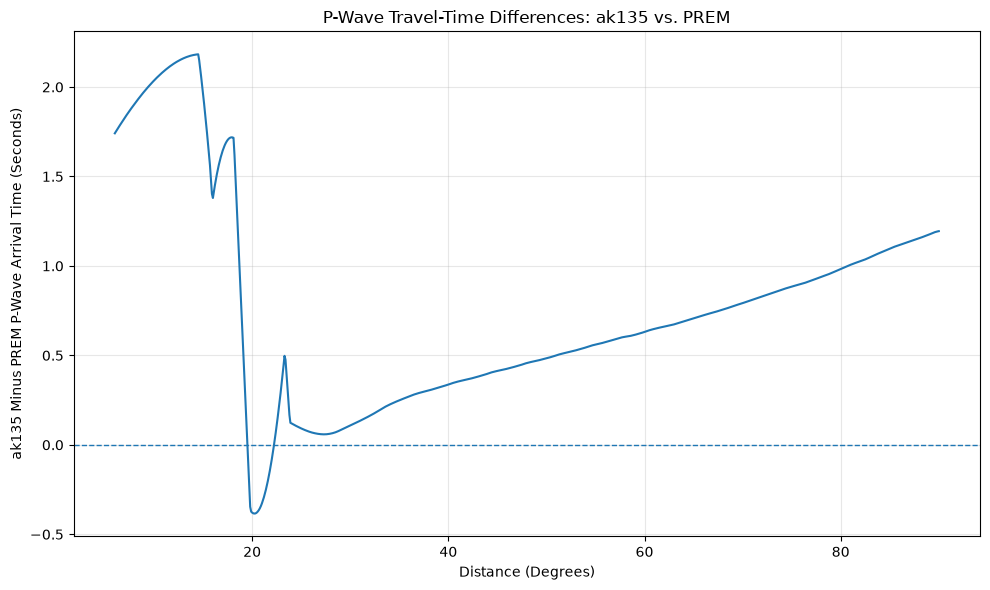

In [68]:
import numpy as np
import matplotlib.pyplot as plt
from obspy.taup import TauPyModel

ak135 = TauPyModel(model="ak135")
prem = TauPyModel(model="prem")

distances = np.arange(6.0, 90.01, 0.1)
ak135_times = []
prem_times = []

for distance in distances:
    parrival_ak135 = ak135.get_travel_times(
        source_depth_in_km=40,
        distance_in_degree=distance,
        phase_list=["P"]
    )
    parrival_prem = prem.get_travel_times(
        source_depth_in_km=40,
        distance_in_degree=distance,
        phase_list=["P"]
    )
    if len(parrival_ak135) > 0:
        ak135_times.append(parrival_ak135[0].time)
    else:
        ak135_times.append(np.nan)

    if len(parrival_prem) > 0:
        prem_times.append(parrival_prem[0].time)
    else:
        prem_times.append(np.nan)

ak135_times = np.array(ak135_times)
prem_times = np.array(prem_times)
time_difference = ak135_times - prem_times

plt.figure(figsize=(10, 6))

plt.plot(
    distances,
    time_difference,
    linewidth=1.5
)

plt.axhline(
    0,
    linestyle="--",
    linewidth=1
)

plt.xlabel("Distance (Degrees)")
plt.ylabel("ak135 Minus PREM P-Wave Arrival Time (Seconds)")
plt.title("P-Wave Travel-Time Differences: ak135 vs. PREM")

plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

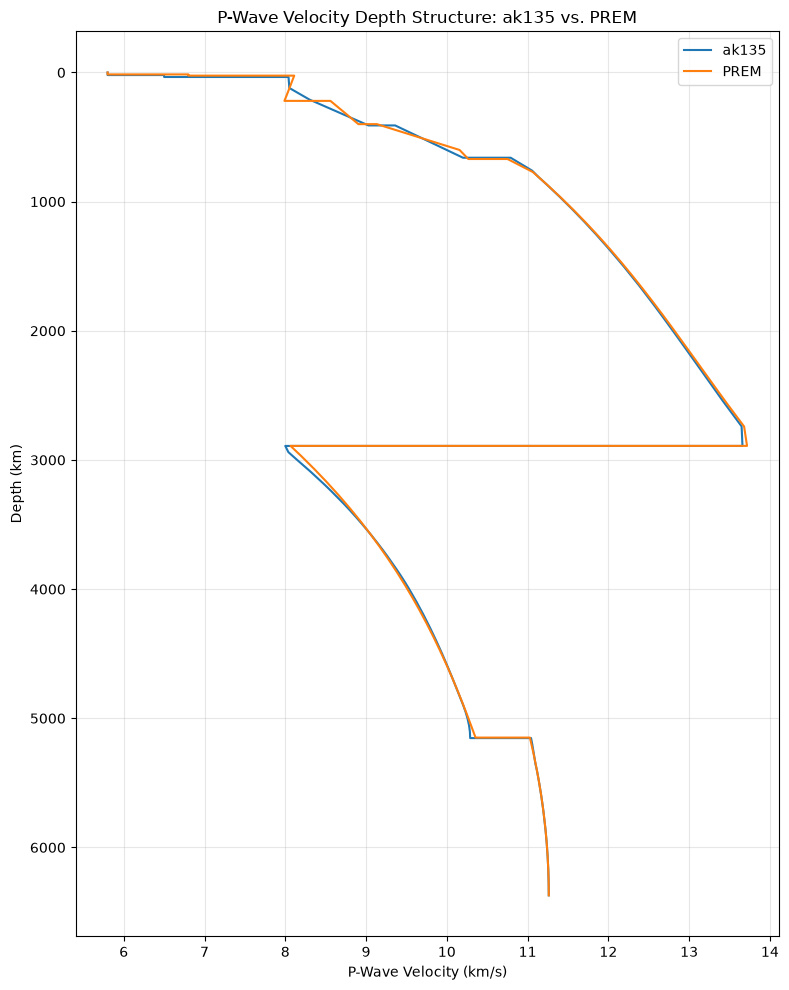

In [62]:
import numpy as np
import matplotlib.pyplot as plt
from obspy.taup import TauPyModel

ak135 = TauPyModel(model="ak135")
prem = TauPyModel(model="prem")

def get_p_velocity_depth(model):
    layers = model.model.s_mod.v_mod.layers
    depth = []
    velocity = []
    for layer in layers:
        depth.append(layer["top_depth"])
        velocity.append(layer["top_p_velocity"])
        depth.append(layer["bot_depth"])
        velocity.append(layer["bot_p_velocity"])
    return np.array(depth), np.array(velocity)

ak_depth, ak_velocity = get_p_velocity_depth(ak135)
prem_depth, prem_velocity = get_p_velocity_depth(prem)
plt.figure(figsize=(8, 10))

plt.plot(
    ak_velocity,
    ak_depth,
    label="ak135",
    linewidth=1.5
)

plt.plot(
    prem_velocity,
    prem_depth,
    label="PREM",
    linewidth=1.5
)

plt.gca().invert_yaxis()

plt.xlabel("P-Wave Velocity (km/s)")
plt.ylabel("Depth (km)")

plt.title("P-Wave Velocity Depth Structure: ak135 vs. PREM")

plt.legend()

plt.grid(alpha=0.3)

plt.tight_layout()

plt.show()

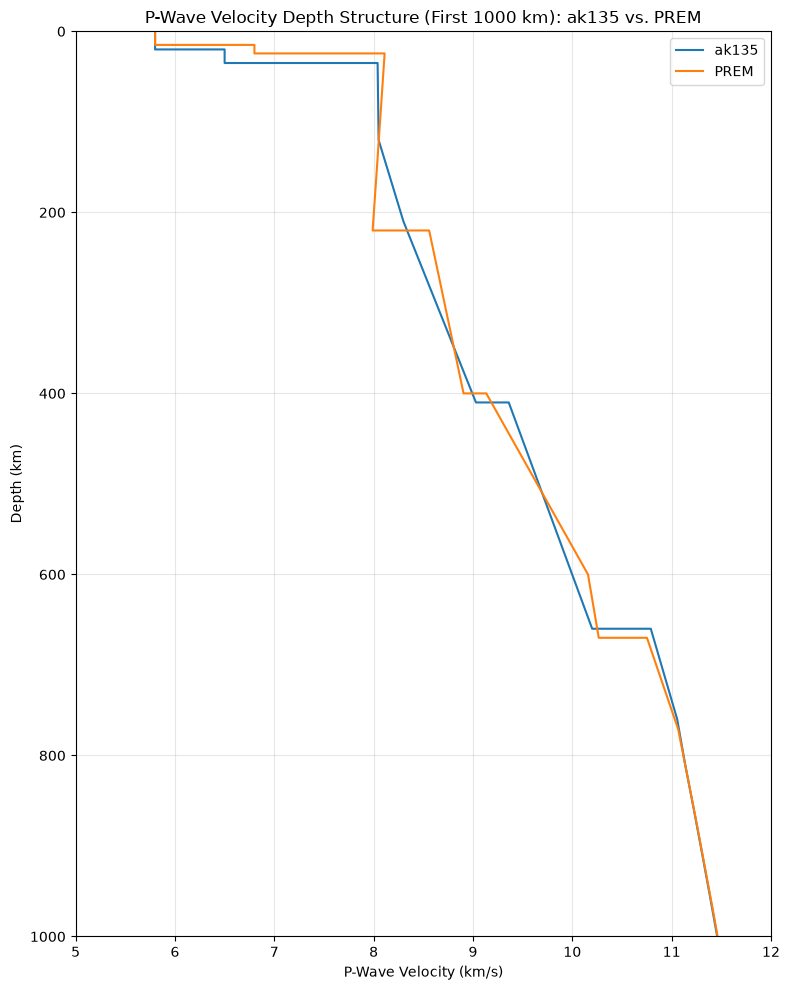

In [69]:
plt.figure(figsize=(8, 10))

plt.plot(
    ak_velocity,
    ak_depth,
    label="ak135",
    linewidth=1.5
)

plt.plot(
    prem_velocity,
    prem_depth,
    label="PREM",
    linewidth=1.5
)

plt.gca().invert_yaxis()

plt.xlabel("P-Wave Velocity (km/s)")
plt.ylabel("Depth (km)")
plt.ylim(1000, 0)
plt.xlim(5, 12)

plt.title("P-Wave Velocity Depth Structure (First 1000 km): ak135 vs. PREM")

plt.legend()

plt.grid(alpha=0.3)

plt.tight_layout()

plt.show()

##### The first plot, titled "P-Wave Travel Time Differences: ak135 vs. PREM," shows both positive and negative values for the differences in arrival time on the y-axis. Positive values (ak135 - PREM > 0) indicate that ak135 has a later P-wave arrival than PREM, while negative values (ak135 - PREM < 0) indicate that ak135 has an earlier P-wave arrival than PREM. The plot generally has positive values on the y-axis, decreasing (mostly, with some hiccups) rapidly until around 20 degrees, where the values dip negative. The values then increase more gradually in the positive from ~25 to 90 degrees. Therefore, the plot predicts that ak135 will have a later P-wave arrival time than PREM in most of the distance range, with a small range (~20-25 degrees) of ak135 having an earlier P-wave arrival time than PREM.

##### The subsequent plots, representing the predicted P-wave velocities at depth of the two models (one having the entire radius of the Earth, and the other having just 1000 km), show the two models having an overall similar shape. In the uppermost mantle, however, PREM predicts a noticeably greater P-wave velocity than ak135. Additionally, as the models go deeper, ak135 predicts a much smoother increase in velocity, while PREM predicts a curve with more sharp increases than gradual ones. Finnally, as the curves get even deeper and go down into the deepest layers of the Earth, the two models are almost identical in their predictions.

##### Overall, the P-wave velocity at depth plots show that the two models have mostly similar velocity structures, but have multiple differences in P-wave velocity at certain depths, which contribute to the travel-time differences between the models. The travel-time difference (ak135 minus PREM), is generally positive, showing that AK135 predicts a slightly later P-wave arrival over most of the distance range. As distance in degrees increases, the P-wave ray path changes and samples progressively different depths, so differences in the velocity structures accumulate along the ray path. This produces the variation in travel-time difference with distance. The noticeable variations around 15 to 25 degrees are likely influenced not only by differences in velocity structure but also by changes in ray geometry and the P-wave travel-time branch.

# All done!